In [5]:
pip install pandas numpy matplotlib seaborn scikit-learn

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier


In [6]:
from google.colab import files

uploaded = files.upload()


Saving KT_GameBox_1.csv to KT_GameBox_1.csv


In [7]:
df = pd.read_csv("KT_GameBox_1.csv")

In [8]:
df.head()

,No.,Time,Source,Destination,Protocol,Length,Info
0,1,2022-10-05 14:28:49.564595,192.0.0.2,10.215.173.2,TCP,60,47254 > 853 [SYN] Seq=0 Win=65535 Len=0 MSS=...
1,2,2022-10-05 14:28:51.317163,10.215.173.1,10.215.173.2,DNS,68,Standard query 0xa610 A gbc.play.ktgamebox.com
2,3,2022-10-05 14:28:51.348247,10.215.173.2,10.215.173.1,DNS,168,Standard query response 0xa610 A gbc.play.ktga...
3,4,2022-10-05 14:28:51.351537,10.215.173.1,211.252.120.14,TCP,60,60014 > 443 [SYN] Seq=0 Win=65535 Len=0 MSS=...
4,5,2022-10-05 14:28:51.372722,211.252.120.14,10.215.173.1,TCP,48,"443 > 60014 [SYN, ACK] Seq=0 Ack=1 Win=2048 ..."


In [9]:
df.shape

(1512728, 7)

In [10]:
df.columns

Index(['No.', 'Time', 'Source', 'Destination', 'Protocol', 'Length', 'Info'], dtype='object')

In [11]:
df.dtypes

,0
No.,int64
Time,object
Source,object
Destination,object
Protocol,object
Length,int64
Info,object


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1512728 entries, 0 to 1512727
Data columns (total 7 columns):
 #   Column       Non-Null Count    Dtype 
---  ------       --------------    ----- 
 0   No.          1512728 non-null  int64 
 1   Time         1512728 non-null  object
 2   Source       1512728 non-null  object
 3   Destination  1512728 non-null  object
 4   Protocol     1512728 non-null  object
 5   Length       1512728 non-null  int64 
 6   Info         1512728 non-null  object
dtypes: int64(2), object(5)
memory usage: 80.8+ MB


In [13]:
df.describe()

,No.,Length
count,1.512728e+06,1.512728e+06
mean,7.563645e+05,1.285918e+03
std,4.366871e+05,1.021589e+03
min,1.000000e+00,3.200000e+01
25%,3.781828e+05,1.300000e+03
50%,7.563645e+05,1.300000e+03
75%,1.134546e+06,1.300000e+03
max,1.512728e+06,1.000000e+04


In [14]:
df.isnull().sum()

,0
No.,0
Time,0
Source,0
Destination,0
Protocol,0
Length,0
Info,0


In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df["Protocol"].unique()

array(['TCP', 'DNS', 'TLSv1.3', 'TLSv1', 'UDP', 'TLSv1.2', 'THRIFT'],
      dtype=object)

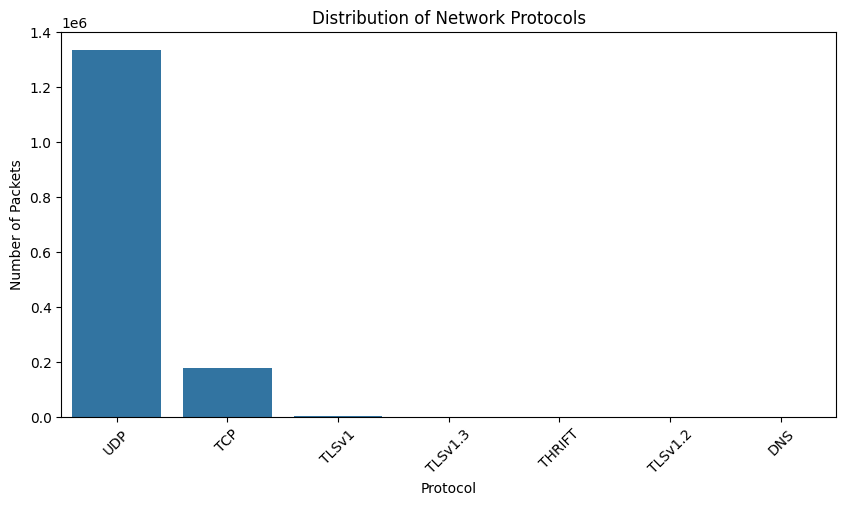

In [17]:
plt.figure(figsize=(10, 5))
sns.countplot(
    data=df,
    x="Protocol",
    order=df["Protocol"].value_counts().index
)

plt.xticks(rotation=45)
plt.title("Distribution of Network Protocols")
plt.xlabel("Protocol")
plt.ylabel("Number of Packets")

plt.show()


In [18]:
df["Length"].describe()

,Length
count,1.512728e+06
mean,1.285918e+03
std,1.021589e+03
min,3.200000e+01
25%,1.300000e+03
50%,1.300000e+03
75%,1.300000e+03
max,1.000000e+04


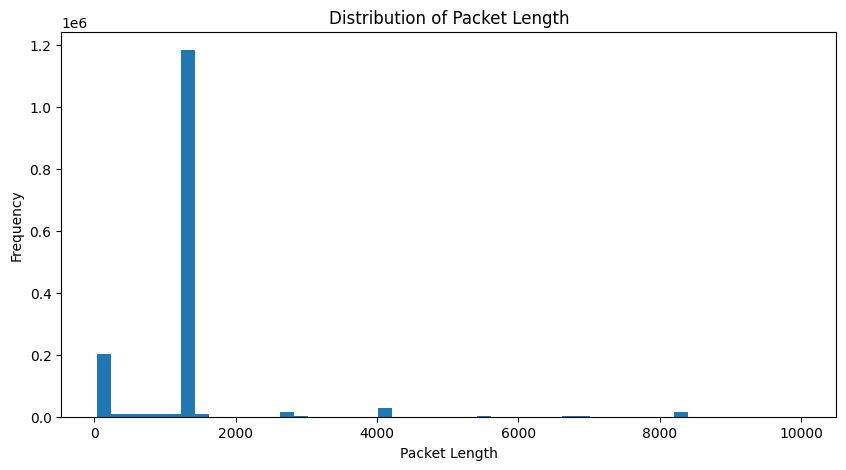

In [19]:
plt.figure(figsize=(10, 5))

plt.hist(df["Length"], bins=50)

plt.title("Distribution of Packet Length")
plt.xlabel("Packet Length")
plt.ylabel("Frequency")

plt.show()


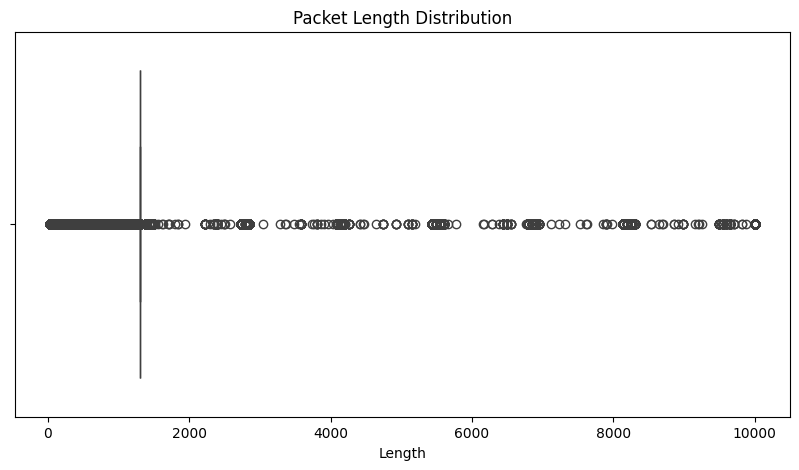

In [20]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["Length"])

plt.title("Packet Length Distribution")

plt.show()

In [21]:
df["Time"].head()

,Time
0,2022-10-05 14:28:49.564595
1,2022-10-05 14:28:51.317163
2,2022-10-05 14:28:51.348247
3,2022-10-05 14:28:51.351537
4,2022-10-05 14:28:51.372722


In [22]:
df["Time"] = pd.to_datetime(df["Time"], errors="coerce")

In [23]:
df["Hour"] = df["Time"].dt.hour
df["Minute"] = df["Time"].dt.minute
df["Second"] = df["Time"].dt.second


In [24]:
df[["Time", "Hour", "Minute", "Second"]].head()

,Time,Hour,Minute,Second
0,2022-10-05 14:28:49.564595,14,28,49
1,2022-10-05 14:28:51.317163,14,28,51
2,2022-10-05 14:28:51.348247,14,28,51
3,2022-10-05 14:28:51.351537,14,28,51
4,2022-10-05 14:28:51.372722,14,28,51


In [25]:
X = df[[
    "Length",
    "Hour",
    "Minute",
    "Second"
]]

y = df["Protocol"]


In [26]:
print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())


Features:
   Length  Hour  Minute  Second
0      60    14      28      49
1      68    14      28      51
2     168    14      28      51
3      60    14      28      51
4      48    14      28      51

Target:
0    TCP
1    DNS
2    DNS
3    TCP
4    TCP
Name: Protocol, dtype: object


In [27]:
print("X shape:", X.shape)
print("y shape:", y.shape)



X shape: (1512728, 4)
y shape: (1512728,)


In [28]:
print(X.isnull().sum())

Length    0
Hour      0
Minute    0
Second    0
dtype: int64


In [29]:
label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)


In [30]:
print(label_encoder.classes_)

['DNS' 'TCP' 'THRIFT' 'TLSv1' 'TLSv1.2' 'TLSv1.3' 'UDP']


In [31]:
print(y_encoded[:20])



[1 0 0 1 1 1 5 1 0 5 1 5 1 5 1 5 1 0 1 5]


In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)


In [33]:
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 1210182
Testing samples: 302546


In [34]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)


MODEL - 1

In [35]:
logistic_model = LogisticRegression(
    max_iter=1000
)

logistic_model.fit(
    X_train_scaled,
    y_train
)


LogisticRegression(max_iter=1000)

In [36]:
y_pred_lr = logistic_model.predict(X_test_scaled)

In [37]:
accuracy_lr = accuracy_score(
    y_test,
    y_pred_lr
)

print("Logistic Regression Accuracy:",
      accuracy_lr)


Logistic Regression Accuracy: 0.9011885795878973


In [38]:
print(
    "Accuracy:",
    accuracy_lr * 100,
    "%"
)


Accuracy: 90.11885795878973 %


In [39]:
print(
    classification_report(
        y_test,
        y_pred_lr,
        target_names=label_encoder.classes_
    )
)


              precision    recall  f1-score   support

         DNS       0.00      0.00      0.00         2
         TCP       1.00      0.16      0.28     35304
      THRIFT       0.00      0.00      0.00         7
       TLSv1       0.00      0.00      0.00       242
     TLSv1.2       0.00      0.00      0.00         3
     TLSv1.3       0.00      0.00      0.00        80
         UDP       0.90      1.00      0.95    266908

    accuracy                           0.90    302546
   macro avg       0.27      0.17      0.18    302546
weighted avg       0.91      0.90      0.87    302546



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


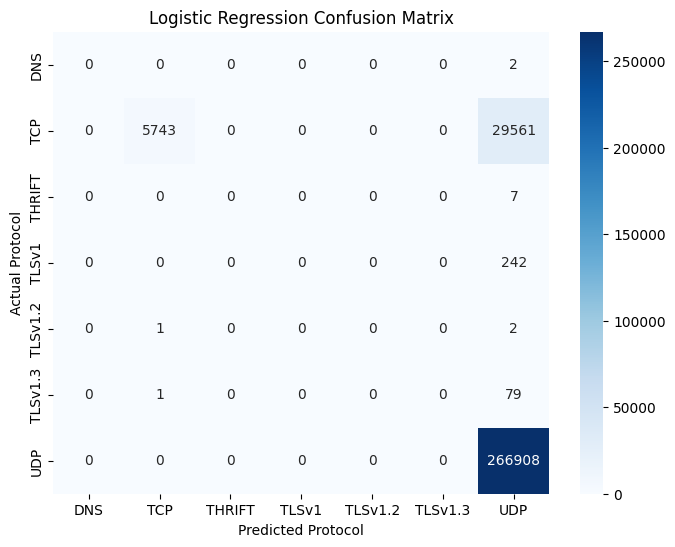

In [40]:
cm = confusion_matrix(
    y_test,
    y_pred_lr
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Protocol")
plt.ylabel("Actual Protocol")
plt.title("Logistic Regression Confusion Matrix")

plt.show()


Model - 2

In [41]:
knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(
    X_train_scaled,
    y_train
)


KNeighborsClassifier()

In [42]:
y_pred_knn = knn_model.predict(
    X_test_scaled
)


In [43]:
accuracy_knn = accuracy_score(
    y_test,
    y_pred_knn
)

print(
    "KNN Accuracy:",
    accuracy_knn * 100,
    "%"
)


KNN Accuracy: 99.72566155229288 %


Model - 3

In [44]:
dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=10
)

dt_model.fit(
    X_train,
    y_train
)


DecisionTreeClassifier(max_depth=10, random_state=42)

In [45]:
y_pred_dt = dt_model.predict(X_test)

In [46]:
accuracy_dt = accuracy_score(
    y_test,
    y_pred_dt
)

print(
    "Decision Tree Accuracy:",
    accuracy_dt * 100,
    "%"
)


Decision Tree Accuracy: 99.94612389520933 %


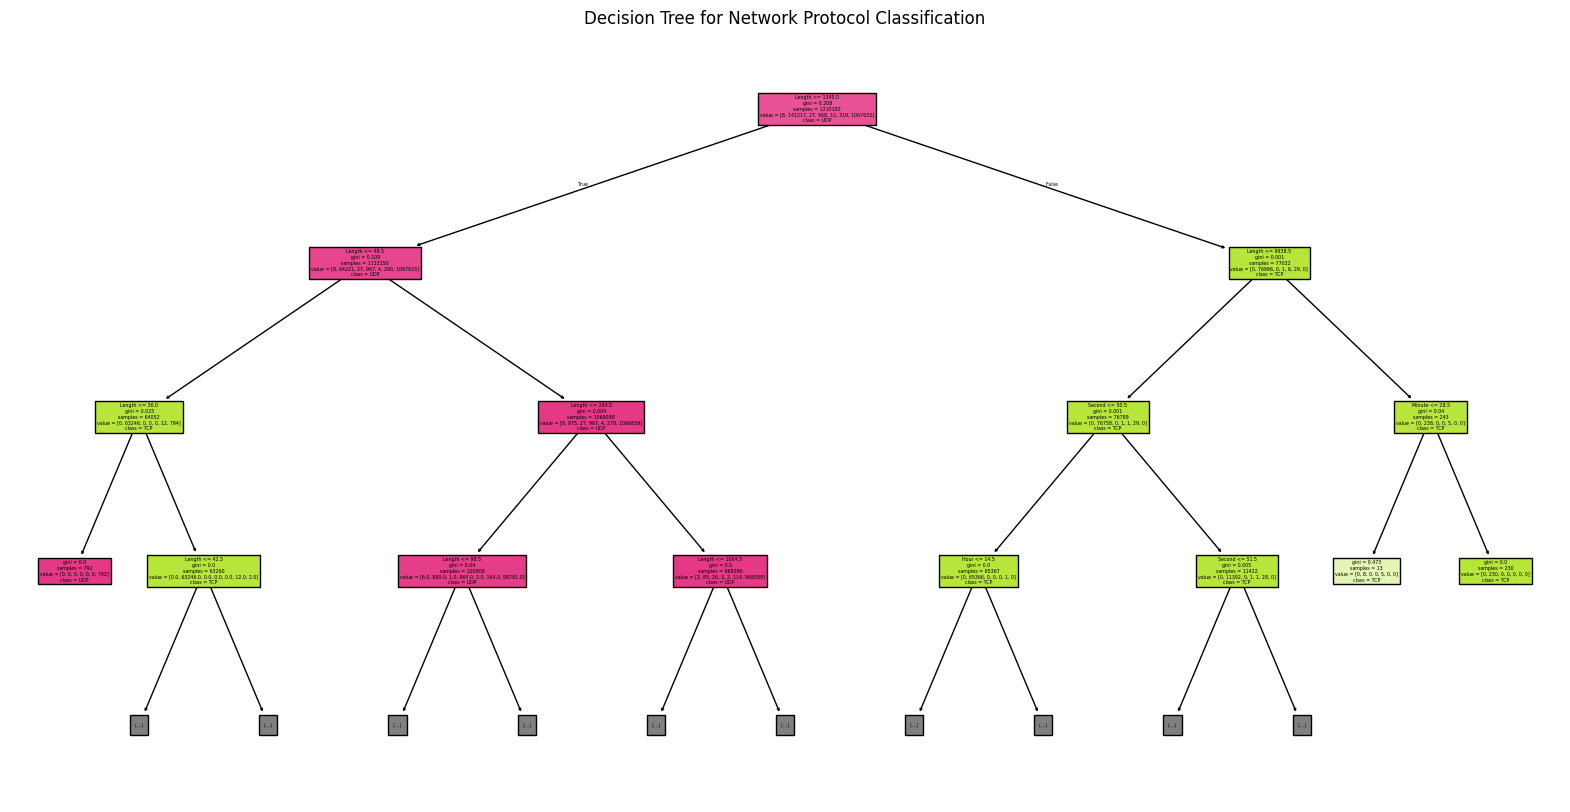

In [47]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=label_encoder.classes_,
    filled=True,
    max_depth=3
)

plt.title("Decision Tree for Network Protocol Classification")

plt.show()


Model - 4

In [48]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)


RandomForestClassifier(n_jobs=-1, random_state=42)

In [49]:
y_pred_rf = rf_model.predict(X_test)

In [50]:
accuracy_rf = accuracy_score(
    y_test,
    y_pred_rf
)

print(
    "Random Forest Accuracy:",
    accuracy_rf * 100,
    "%"
)


Random Forest Accuracy: 99.93852174545358 %


Comparision between Model

In [51]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_lr,
        accuracy_knn,
        accuracy_dt,
        accuracy_rf
    ]
})

results["Accuracy (%)"] = (
    results["Accuracy"] * 100
)


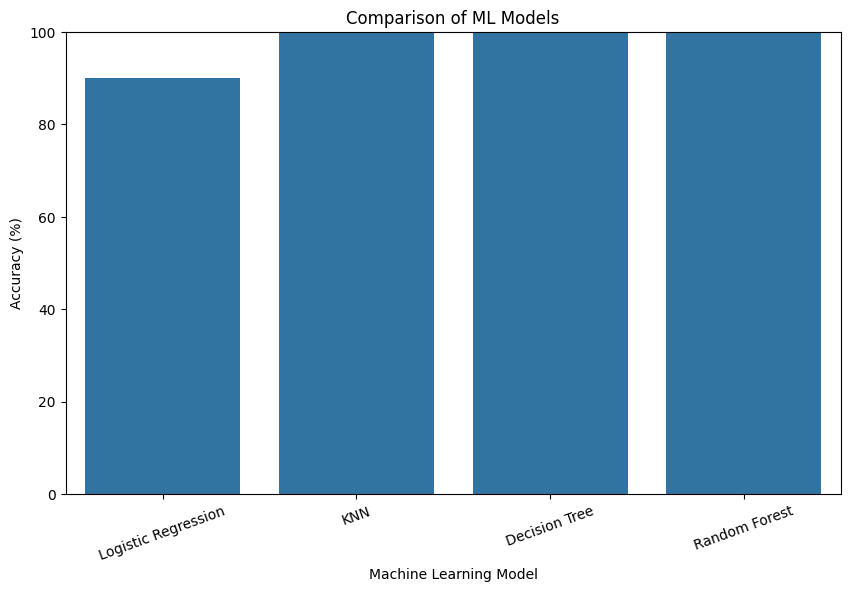

In [52]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results,
    x="Model",
    y="Accuracy (%)"
)

plt.xticks(rotation=20)
plt.ylim(0, 100)

plt.title("Comparison of ML Models")
plt.ylabel("Accuracy (%)")
plt.xlabel("Machine Learning Model")

plt.show()


Best Model

In [53]:
best_model = results.loc[
    results["Accuracy"].idxmax()
]

print("Best Model:")
print(best_model)


Best Model:
Model           Decision Tree
Accuracy             0.999461
Accuracy (%)        99.946124
Name: 2, dtype: object


In [54]:
importance = rf_model.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)


  Feature  Importance
0  Length    0.992227
2  Minute    0.005032
3  Second    0.002161
1    Hour    0.000579


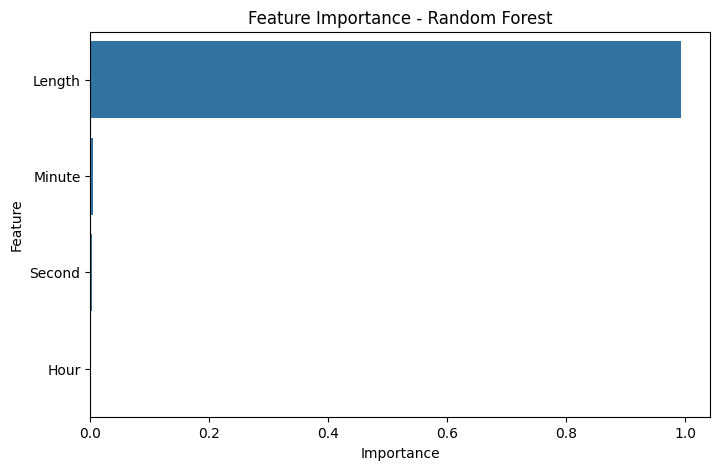

In [55]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Random Forest")

plt.show()


In [61]:
print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=label_encoder.classes_
    )
)




              precision    recall  f1-score   support

         DNS       0.33      0.50      0.40         2
         TCP       1.00      1.00      1.00     35304
      THRIFT       0.00      0.00      0.00         7
       TLSv1       0.86      0.74      0.79       242
     TLSv1.2       0.00      0.00      0.00         3
     TLSv1.3       0.84      0.65      0.73        80
         UDP       1.00      1.00      1.00    266908

    accuracy                           1.00    302546
   macro avg       0.58      0.55      0.56    302546
weighted avg       1.00      1.00      1.00    302546



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


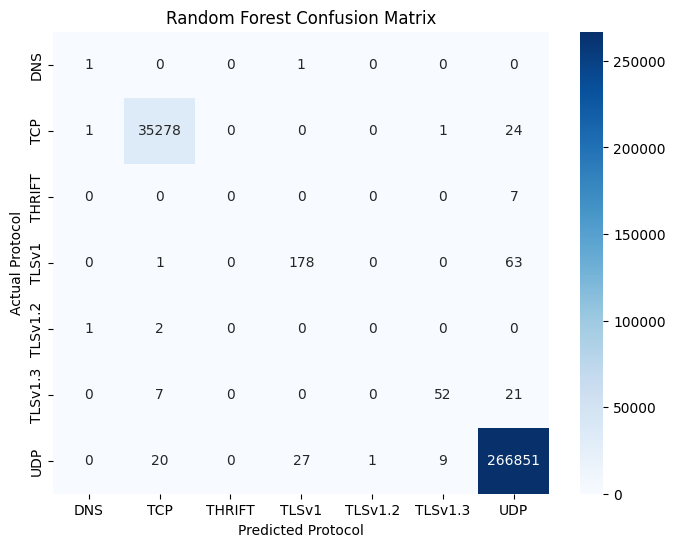

In [62]:
cm_rf = confusion_matrix(
    y_test,
    y_pred_rf
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Protocol")
plt.ylabel("Actual Protocol")

plt.title(
    "Random Forest Confusion Matrix"
)

plt.show()

Predict new packet

In [58]:
new_packet = pd.DataFrame({
    "Length": [64],
    "Hour": [10],
    "Minute": [30],
    "Second": [15]
})


In [59]:
prediction = rf_model.predict(
    new_packet
)


In [60]:
predicted_protocol = label_encoder.inverse_transform(
    prediction
)

print(
    "Predicted Protocol:",
    predicted_protocol[0]
)


Predicted Protocol: UDP
